# FD001 acquisition and exploratory data analysis

Source: NASA Prognostics Center of Excellence, *Turbofan Engine Degradation Simulation Data Set* (Saxena and Goebel, 2008). Retrieved 2026-08-28 from the official NASA-linked archive. This notebook uses only `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt`. One row is one observation of one engine at one operational cycle. No model is trained here.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from ml.data.cmapss import SETTING_COLUMNS, SENSOR_COLUMNS, add_linear_train_rul, load_fd001
RAW_DIR = ROOT / 'data' / 'raw' / 'source' / 'CMAPSSData'
fd001 = load_fd001(RAW_DIR)
train, test, test_rul = fd001.train, fd001.test, fd001.test_rul
[(p.name, p.stat().st_size) for p in [RAW_DIR/'train_FD001.txt', RAW_DIR/'test_FD001.txt', RAW_DIR/'RUL_FD001.txt']]

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Sai\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


[('train_FD001.txt', 3515356),
 ('test_FD001.txt', 2228855),
 ('RUL_FD001.txt', 429)]

## Integrity, schema, and row semantics

In [2]:
integrity = pd.DataFrame({
    'rows': [len(train), len(test)],
    'units': [train.unit_id.nunique(), test.unit_id.nunique()],
    'columns': [train.shape[1], test.shape[1]],
    'missing_cells': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'duplicate_rows': [int(train.duplicated().sum()), int(test.duplicated().sum())],
}, index=['train', 'test'])
display(integrity)
display(train.dtypes.value_counts().rename('column_count'))
display(train.iloc[[16]].T.rename(columns={16: 'unit_1_cycle_17'}))

,rows,units,columns,missing_cells,duplicate_rows
train,20631,100,26,0,0
test,13096,100,26,0,0


float64    22
int64       4
Name: column_count, dtype: int64

,unit_1_cycle_17
unit_id,1.0000
cycle,17.0000
operational_setting_1,0.0002
operational_setting_2,0.0002
operational_setting_3,100.0000
sensor_1,518.6700
sensor_2,642.5800
sensor_3,1584.9600
sensor_4,1399.9500
sensor_5,14.6200


## Trajectory lengths

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: trajectory_length, dtype: float64

,min_cycle,max_cycle,trajectory_length,role
unit_id,,,,
39,1,128,128,shortest
26,1,199,199,nearest_median
69,1,362,362,longest


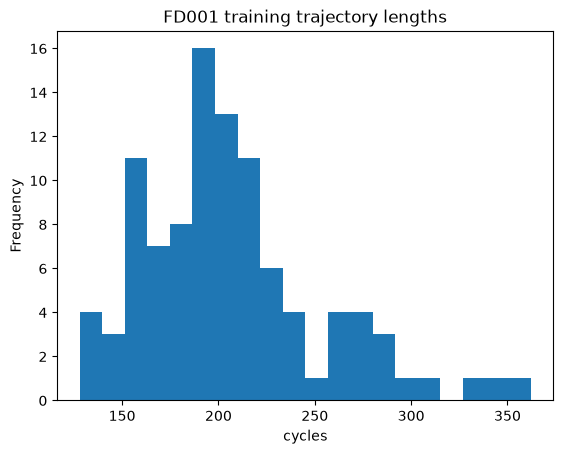

In [3]:
lifetimes = train.groupby('unit_id').cycle.agg(min_cycle='min', max_cycle='max', trajectory_length='count')
display(lifetimes.trajectory_length.describe())
short_id = lifetimes.trajectory_length.idxmin()
long_id = lifetimes.trajectory_length.idxmax()
median_life = lifetimes.trajectory_length.median()
median_id = (lifetimes.trajectory_length - median_life).abs().idxmin()
display(lifetimes.loc[[short_id, median_id, long_id]].assign(role=['shortest', 'nearest_median', 'longest']))
lifetimes.trajectory_length.plot.hist(bins=20, title='FD001 training trajectory lengths'); plt.xlabel('cycles'); plt.show()

## Feature statistics and low-variance evidence

In [4]:
features = SETTING_COLUMNS + SENSOR_COLUMNS
feature_stats = train[features].describe(percentiles=[.01,.25,.5,.75,.99]).T
feature_stats['unique'] = train[features].nunique()
feature_stats['missing'] = train[features].isna().sum()
feature_stats['range'] = feature_stats['max'] - feature_stats['min']
display(feature_stats)
constant = feature_stats.index[feature_stats['unique'] == 1].tolist()
near_constant = feature_stats.index[(feature_stats['unique'] > 1) & (feature_stats['std'] < 1e-3)].tolist()
print('constant:', constant)
print('near-constant by raw std < 1e-3:', near_constant)

,count,mean,std,min,1%,25%,50%,75%,99%,max,unique,missing,range
operational_setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0051,-0.0015,0.0000,0.0015,0.00500,0.0087,158,0,0.0174
operational_setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0005,-0.0002,0.0000,0.0003,0.00050,0.0006,13,0,0.0012
operational_setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000,100.00000,100.0000,1,0,0.0000
sensor_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700,518.67000,518.6700,1,0,0.0000
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,641.6500,642.3250,642.6400,643.0000,643.93000,644.5300,310,0,3.3200
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1577.6130,1586.2600,1590.1000,1594.3800,1605.87100,1616.9100,3012,0,45.8700
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1391.8830,1402.3600,1408.0400,1414.5550,1431.51700,1441.4900,4051,0,59.2400
sensor_5,20631.0,14.620000,5.329200e-15,14.6200,14.6200,14.6200,14.6200,14.6200,14.62000,14.6200,1,0,0.0000
sensor_6,20631.0,21.609803,1.388985e-03,21.6000,21.6000,21.6100,21.6100,21.6100,21.61000,21.6100,2,0,0.0100
sensor_7,20631.0,553.367711,8.850923e-01,549.8500,551.1600,552.8100,553.4400,554.0100,555.07000,556.0600,513,0,6.2100


constant: ['operational_setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
near-constant by raw std < 1e-3: ['operational_setting_2']


## Temporal behavior and operating settings

,count,mean,std,min,25%,50%,75%,max,unique
operational_setting_1,20631.0,-0.000009,0.002187,-0.0087,-0.0015,0.0,0.0015,0.0087,158
operational_setting_2,20631.0,0.000002,0.000293,-0.0006,-0.0002,0.0,0.0003,0.0006,13
operational_setting_3,20631.0,100.000000,0.000000,100.0000,100.0000,100.0,100.0000,100.0000,1


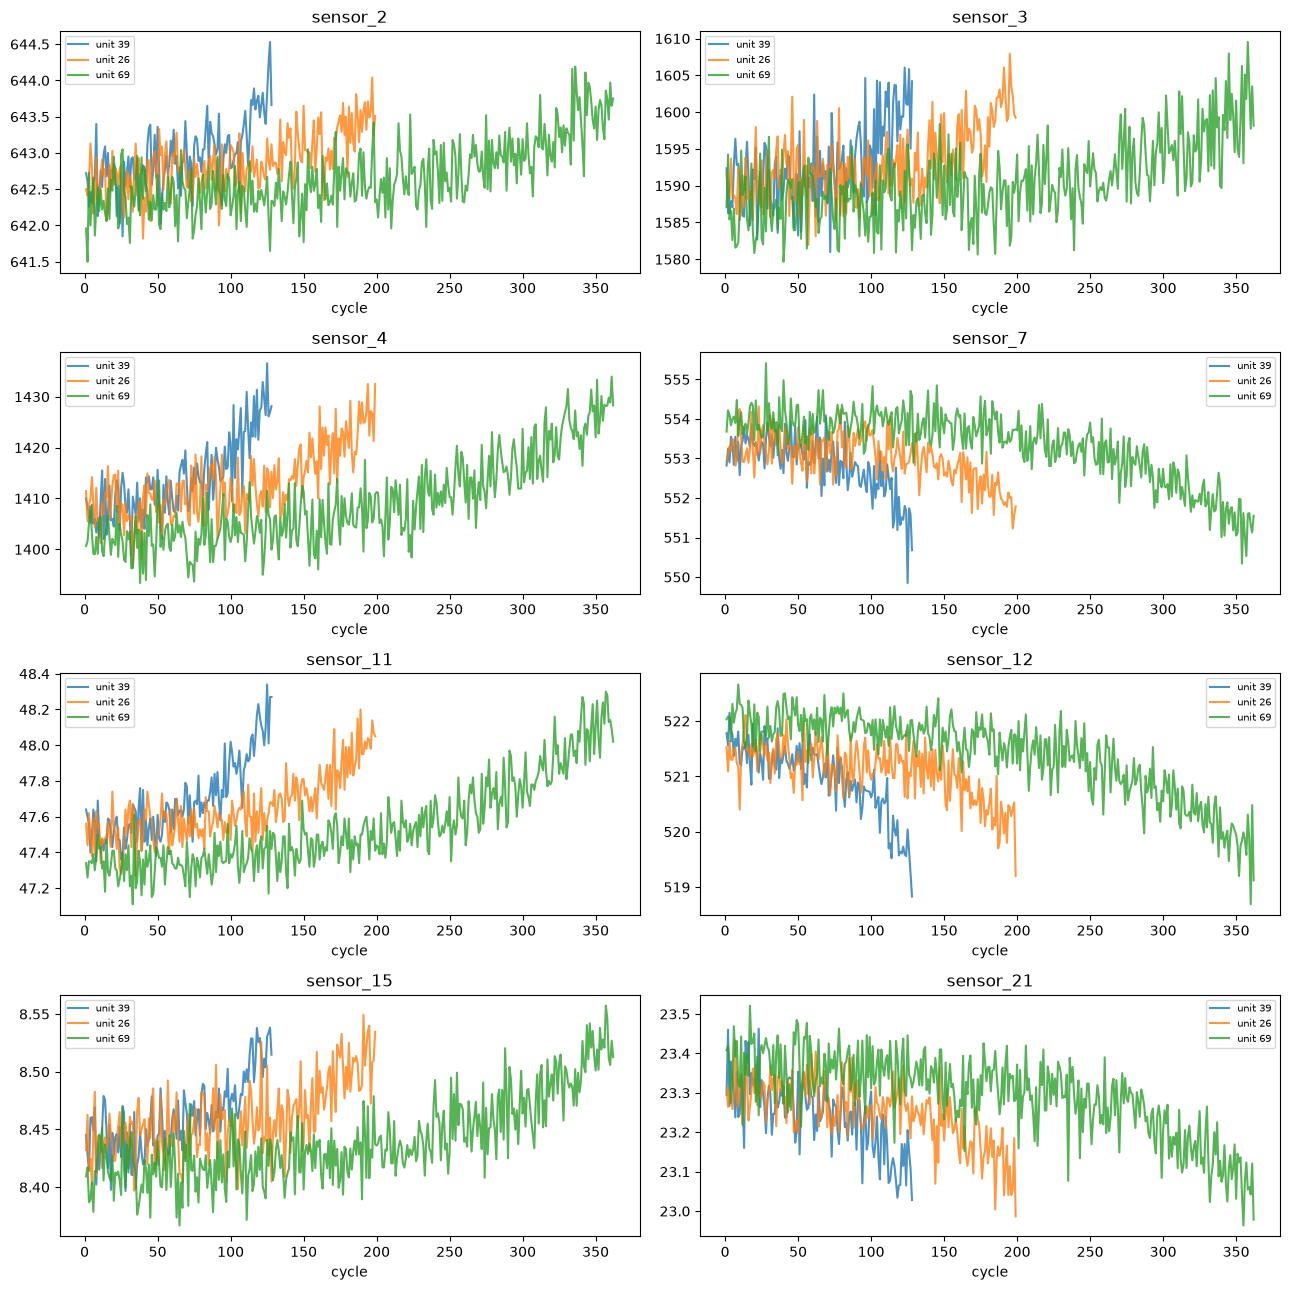

sensor_12   -0.701873
sensor_7    -0.685233
sensor_21   -0.666816
sensor_3     0.616009
sensor_2     0.632123
sensor_15    0.672931
sensor_4     0.711539
sensor_11    0.727496
Name: correlation_with_normalized_life_progress, dtype: float64

In [5]:
display(train[SETTING_COLUMNS].describe().T.assign(unique=train[SETTING_COLUMNS].nunique()))
selected_sensors = ['sensor_2','sensor_3','sensor_4','sensor_7','sensor_11','sensor_12','sensor_15','sensor_21']
fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=False)
for sensor, ax in zip(selected_sensors, axes.flat):
    for unit in [short_id, median_id, long_id]:
        part = train[train.unit_id == unit]
        ax.plot(part.cycle, part[sensor], alpha=.8, label=f'unit {unit}')
    ax.set_title(sensor); ax.set_xlabel('cycle'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
trend = train.assign(progress=train.cycle / train.groupby('unit_id').cycle.transform('max'))
trend_corr = trend[selected_sensors + ['progress']].corr()['progress'].drop('progress').sort_values()
display(trend_corr.rename('correlation_with_normalized_life_progress'))

## Linear training RUL and target distribution

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
10%         20.000000
25%         51.000000
50%        103.000000
75%        155.000000
90%        198.000000
max        361.000000
Name: rul, dtype: float64

low-RUL rows (<=30): 3100 of 20631


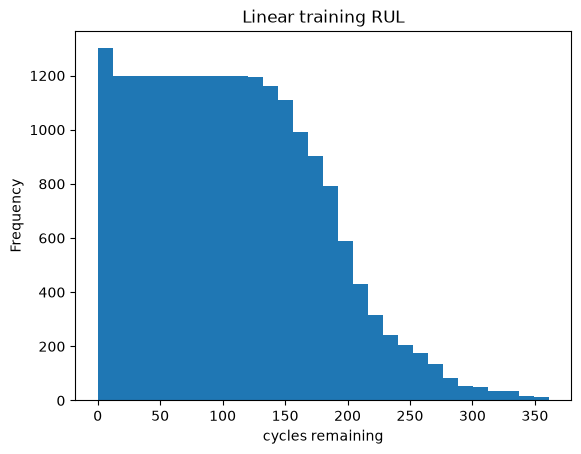

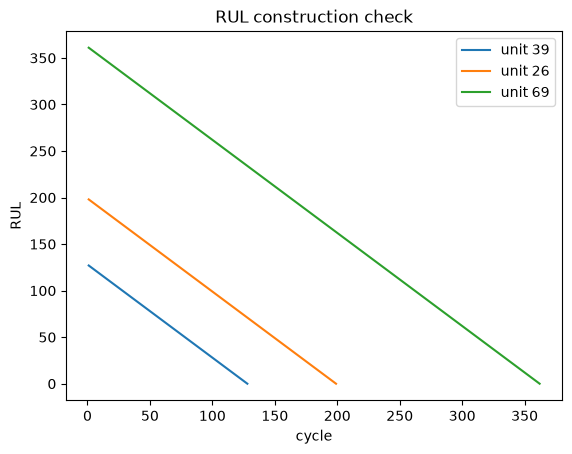

In [6]:
train_rul = add_linear_train_rul(train)
display(train_rul.rul.describe(percentiles=[.1,.25,.5,.75,.9]))
print('low-RUL rows (<=30):', int((train_rul.rul <= 30).sum()), 'of', len(train_rul))
train_rul.rul.plot.hist(bins=30, title='Linear training RUL'); plt.xlabel('cycles remaining'); plt.show()
for unit in [short_id, median_id, long_id]:
    part = train_rul[train_rul.unit_id == unit]
    plt.plot(part.cycle, part.rul, label=f'unit {unit}')
plt.title('RUL construction check'); plt.xlabel('cycle'); plt.ylabel('RUL'); plt.legend(); plt.show()

## Leakage-safe split, scaling, windows, and baseline plan

The deterministic development split below assigns complete engines 1–80 to training and 81–100 to validation. No rows or windows from one engine cross the boundary. Any scaler must be fitted only on engines 1–80, then applied unchanged to validation and the official test set. Raw feature scales differ substantially, so scaling is needed for distance/gradient-based models. Constant features are candidates for removal, but removal will occur only in a later preprocessing phase with the evidence recorded here.

In [7]:
train_units = list(range(1, 81)); validation_units = list(range(81, 101))
print('training units:', train_units)
print('validation units:', validation_units)
def window_summary(frame, window):
    lengths = frame.groupby('unit_id').size()
    counts = (lengths - window + 1).clip(lower=0)
    targets = []
    for unit, count in counts.items():
        if count:
            targets.extend(add_linear_train_rul(frame[frame.unit_id == unit]).rul.iloc[window-1:].tolist())
    return {'window': window, 'sequences': int(counts.sum()), 'engines_too_short': int((lengths < window).sum()),
            'target_min': min(targets), 'target_median': float(np.median(targets)), 'target_max': max(targets)}
display(pd.DataFrame(window_summary(train, w) for w in [20, 30, 50]))

training units: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80]
validation units: [81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100]


,window,sequences,engines_too_short,target_min,target_median,target_max
0,20,18731,0,0,93.0,342
1,30,17731,0,0,88.0,332
2,50,15731,0,0,78.0,312


### Decisions and unresolved questions

- Linear uncapped RUL is retained as the transparent initial target definition; whether an early-life cap improves the learning objective remains an experiment for the baseline phase, not an EDA assumption.
- Candidate windows 20, 30, and 50 are feasible; the final choice must consider validation performance and near-failure errors, not only sample count.
- Temporal plots and correlations show degradation signal in several sensors, but trajectories are noisy and not uniformly monotonic. This supports testing sequence models later, only after baselines.
- FD001 settings are effectively fixed/near-fixed, consistent with one operating condition; they offer little variation here but should not be removed from broader subsets by extrapolation.
- Leakage risks: row-wise splitting, overlapping windows across splits, fitting feature selection/scalers on validation/test, and using official test RUL during feature decisions.
- Baseline plan: training-median RUL sanity predictor, linear regression, then a tree regressor using current-cycle features; report MAE/RMSE overall and for RUL <= 30 before considering a sequence model.
- Open questions: capped versus linear RUL, best scaler, final window length, and whether low-variance nonconstant features add validation value.